# Traditional RAG

A baseline RAG pipeline built with LangGraph. Loads PDF documents, splits and embeds them into a FAISS
vector store, and wires a `retrieve -> generate` graph to answer questions grounded in the retrieved context.

This phase establishes the foundation that `phase_02` builds upon with a corrective layer.

## 1. Load Documents

Load the three ML/DL textbooks from the `../data/` directory using `PyPDFLoader`.

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

from langchain_community.document_loaders import PyPDFLoader

In [ ]:
docs = (
    PyPDFLoader("../data/deep_learning_book.pdf").load()
    + PyPDFLoader("../data/hands_on_ml.pdf").load()
    + PyPDFLoader("../data/pattern_recognition_and_ml_book.pdf").load()
)

In [ ]:
print(f"Loaded {len(docs)} pages across 3 PDFs.")

Each PDF page is loaded as a `Document` object carrying the raw text and source metadata.
The three books together form the knowledge base the retriever will search over.

## 2. Chunk Documents

Split the loaded documents into smaller overlapping chunks for embedding.
A chunk size of 900 characters with 150-character overlap balances context richness and retrieval precision.

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [5]:
chunks = RecursiveCharacterTextSplitter(
    chunk_size=900, chunk_overlap=150
).split_documents(docs)

# Clean the chunk texts to avoid any UnicodeEncodeError (surrogates from PDF extraction)

for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [ ]:
print(f"Split into {len(chunks)} chunks (chunk_size=900, overlap=150).")

Each chunk is a fixed-size window of text with slight overlap to preserve context at boundaries.
These chunks are the unit of embedding -- what gets indexed in the vector store.

## 3. Embeddings

Set up the Azure OpenAI embeddings model (`text-embedding-3-large`).
Credentials are read from `.env` via `python-dotenv`.

In [7]:
import os
from dotenv import load_dotenv
from langchain_openai import OpenAIEmbeddings

load_dotenv()

True

In [8]:
# Embeddings
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-large",
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    base_url=os.getenv("AZURE_OPENAI_ENDPOINT"),
    check_embedding_ctx_length=False,
)

The embeddings model maps text to dense numerical vectors. Semantic similarity between query
and chunk vectors drives retrieval -- semantically close chunks rank higher than keyword-matched ones.

## 4. Vector Store

Build or load a FAISS index from the embedded chunks.
If a persisted index already exists in `../vector_store/`, it is loaded to avoid re-embedding on every run.

In [ ]:
from langchain_community.vectorstores import FAISS

In [ ]:
VECTOR_STORE_PATH = "../vector_store"

faiss_index_exists = os.path.isfile(os.path.join(VECTOR_STORE_PATH, "index.faiss"))

if faiss_index_exists:
    vector_store = FAISS.load_local(
        VECTOR_STORE_PATH, embeddings, allow_dangerous_deserialization=True
    )
else:
    vector_store = FAISS.from_documents(chunks, embeddings)
    vector_store.save_local(VECTOR_STORE_PATH)

The FAISS index is now ready. On first run it embeds all chunks and persists the index to `../vector_store/`;
subsequent runs skip re-embedding and load the saved index directly -- saving significant time and cost.

## 5. Retriever

Wrap the vector store as a LangChain retriever.
Similarity search returns the top `k=4` most relevant chunks for a given query.

In [11]:
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

The retriever wraps the vector store with a search interface. At query time it embeds the question
and returns the `k` most semantically similar chunks as `Document` objects ready for the generation step.

## 6. Language Model

Instantiate the Azure OpenAI chat model used to generate answers from retrieved context.

In [12]:
from langchain_openai import ChatOpenAI

In [ ]:
llm = ChatOpenAI(
    model="gpt-6-luna",
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    base_url=os.getenv("AZURE_OPENAI_ENDPOINT"),
)

The LLM handles the generation step -- it reads the retrieved context and composes a grounded answer.
The same instance is reused across all invocations of the graph.

## 7. Graph State and Nodes

Define the LangGraph state schema and the two node functions:

- `retrieve` -- fetches relevant chunks from the vector store for the given question
- `generate` -- constructs an answer from the retrieved chunks using the LLM

The prompt instructs the LLM to answer only from context, reducing hallucination on out-of-context questions.

In [14]:
from typing import TypedDict, List
from langchain_core.documents import Document

In [15]:
class State(TypedDict):
    question: str
    docs: List[Document]
    answer: str

In [16]:
def retrieve(state):
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [17]:
from langchain_core.prompts import ChatPromptTemplate

In [18]:
prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer only from the context. If not in context, say you don't know",
        ),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)

In [19]:
def generate(state):
    context = "\n\n".join(d.page_content for d in state["docs"])
    out = (prompt | llm).invoke({"question": state["question"], "context": context})
    return {"answer": out.content}

`retrieve` and `generate` implement the full RAG loop: pull context, then synthesize. Both functions
read from and write to the shared `State` dict that LangGraph passes between nodes.

## 8. Build the Graph

Assemble the nodes into a LangGraph `StateGraph` and compile it.
The execution flow is linear: `START -> retrieve -> generate -> END`.

In [20]:
from langgraph.graph import StateGraph, START, END

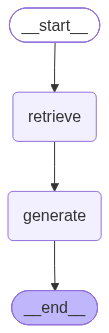

In [21]:
builder = StateGraph(State)

# Add nodes
builder.add_node("retrieve", retrieve)
builder.add_node("generate", generate)

# Add Edges
builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "generate")
builder.add_edge("generate", END)

graph = builder.compile()

graph

The compiled graph is a runnable pipeline. Calling `graph.invoke(state)` triggers the full
`retrieve -> generate` flow and returns the updated state with `answer` populated.

## 9. Run the Pipeline

Three test queries that walk through the pipeline's behavior across different question types.

In [ ]:
def process_response(q: str):
    input_state = {"question": q, "docs": [], "answer": ""}
    response = graph.invoke(input_state)
    return response


def view_retrieved_docs(resp: dict, k: int = 4):
    for i in range(k):
        print(resp["docs"][i].page_content)
        print("*" * 100)

### Test 1: In-context question

A question well within the scope of the loaded textbooks.
The LLM should ground its answer entirely in the retrieved chunks.

In [34]:
q = "Explain the bias-variance trade-off"

In [35]:
response = process_response(q)
answer = response["answer"]
print(answer)

The **bias–variance trade-off** describes how model complexity affects generalization error, which can be viewed as the sum of **bias**, **variance**, and **irreducible error**:

- **Bias** comes from assumptions that are too restrictive—for example, treating a nonlinear relationship as linear. High bias often leads to underfitting.
- **Variance** comes from being overly sensitive to small changes in the training data. Complex models with many degrees of freedom often have high variance and may overfit.
- **Irreducible error** comes from noise in the data itself; it cannot be removed by choosing a different model.

Increasing model complexity typically lowers bias but raises variance. Reducing complexity does the opposite. The goal is to balance the two so the model generalizes well, rather than simply fitting the training data closely.


In [36]:
view_retrieved_docs(response)

10 This notion of bias is not to be confused with the bias term of linear models.
Figure 4-16. Learning curves for the polynomial model
One way to improve an overfitting model is to feed it more training
da
ta until the validation error reaches the training error.
The Bias/Variance Tradeoff
An importan
t theoretical result of statistics and Machine Learning is the fact that a
model’s generaliza
tion error can be expressed as the sum of three very different
errors:
Bias
This part of the generalization error is due to wrong assumptions, such as assum‐
ing that the data is linear when it is actually quadratic. A high-bias model is most
likely to underfit the training data.10
Variance
This part is due to the model’s excessive sensitivity to small variations in the
training data. A model with many degrees of freedom (such as a high-degree pol‐
****************************************************************************************************
Irreducible error
This part is due to the noisin

The answer is grounded in the retrieved documents -- the LLM correctly uses context rather than pretraining knowledge.

---

### Test 2: Out-of-context question

A question completely outside the scope of the loaded textbooks.
The LLM should decline to answer since no relevant context is retrieved.

In [37]:
q = "What are the top AI news from last month"

In [38]:
response = process_response(q)
answer = response["answer"]
print(answer)

I don’t know. The context contains background on deep learning, but no AI news from last month.


In [39]:
view_retrieved_docs(response)

growthinitspopularityandusefulness,dueinlargeparttomorepowerfulcom-
puters,largerdatasetsandtechniquestotraindeepernetworks.Theyearsahead
arefullofchallengesandopportunitiestoimprovedeeplearningevenfurtherand
bringittonewfrontiers.
26
****************************************************************************************************
4.DeepBoltzmannmachine(SalakhutdinovandHinton2009a,)
5.Unsupervisedconvolutionalnetwork( ,)Jarrettetal.2009
6.GPU-acceleratedmultilayerperceptron( ,)Ciresanetal.2010
7.Distributedautoencoder( ,)Leetal.2012
8.Multi-GPUconvolutionalnetwork( ,)Krizhevskyetal.2012
9.COTSHPCunsupervisedconvolutionalnetwork( ,)Coatesetal.2013
10.GoogLeNet( ,)Szegedyetal.2014a
24
****************************************************************************************************
CHAPTER1.INTRODUCTION
AI
Machine learning
Representation learning
Deep learning
Example:
Knowledge
bases
Example:
Logistic
regression
Example:
Shallow
autoencodersExample:
MLPs
Figure1.4:AVenndiagramshowi

The LLM correctly declines -- it found no relevant context and says so explicitly.

---

### Test 3: Edgy question -- parametric knowledge injection

A question that sits at the edge of the loaded content. The textbooks cover NLP and language models at a
foundational level, but not LLMs specifically. This tests whether the LLM stays within the retrieved context
or fills in the gap using its pretraining knowledge (*parametric knowledge injection*).

In [45]:
q = "How NLP is connected with LLMs?"

In [46]:
response = process_response(q)
answer = response["answer"]
print(answer)

NLP is the field of using computers to understand and produce human language. LLMs are a type of neural language model used for NLP: they learn patterns in sequences of words, characters, or bytes and assign probabilities to possible sequences. Their learned representations let them generalize between similar words and contexts. These models can support NLP applications such as machine translation and parsing.


In [47]:
view_retrieved_docs(response)

CHAPTER12.APPLICATIONS
12.4.2NeuralLanguageModels
NeurallanguagemodelsorNLMsare aclassoflanguagemodeldesigned
toovercomethecurseofdimensionalityproblemformodelingnaturallanguage
sequencesbyusingadistributedrepresentationofwords( ,).Bengioetal.2001
Unlikeclass-basedn-grammodels,neurallanguagemodelsareabletorecognize
thattwowordsaresimilarwithoutlosingtheabilitytoencodeeachwordasdistinct
fromtheother.Neurallanguagemodelssharestatisticalstrengthbetweenone
word(anditscontext)andothersimilarwordsandcontexts.Thedistributed
representationthemodellearnsforeachwordenablesthissharingbyallowingthe
modeltotreatwordsthathavefeaturesincommonsimilarly.Forexample,ifthe
worddogandthewordcatmaptorepresentationsthatsharemanyattributes,then
sentencesthatcontainthewordcatcaninformthepredictionsthatwillbemadeby
themodelforsentencesthatcontaintheworddog,andvice-versa.Becausethere
****************************************************************************************************
CHAPTER12.APPLICATIONS
inform

**Observation: Parametric Knowledge Injection**

For `"How NLP is connected with LLMs?"`, the LLM answers using pretraining knowledge -- not the retrieved chunks --
despite being instructed to answer only from context.

This is *parametric knowledge injection*: the model injects facts learned during training into what should be
a context-grounded answer. It can appear harmless, but in production the same behaviour causes real problems:

> A user asks about a specific cashback offer. No matching document is retrieved. The LLM fabricates a
> plausible-sounding but incorrect policy -- and the user acts on it.

**This is the core problem that `phase_02` addresses** -- by grading retrieved documents for relevance,
rewriting the query when they are poor, and falling back to web search when the vector store cannot help.